# Projet signaux 3 — traitement d'une photo de pièce

`main.ipynb` est le fichier central : on y choisit la photo et on enchaîne les traitements. Les fonctions de traitement sont rangées dans des fichiers Python séparés, dans le dossier `modules/`.

Le principe est : une fonction reçoit une image, fait une étape, puis la **renvoie**. On garde ce résultat dans une variable pour l'étape suivante.


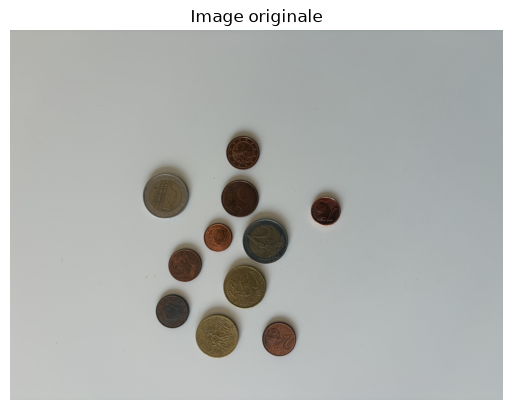

In [1]:
# Charger et afficher l’image originale

from pathlib import Path
import matplotlib.pyplot as plt

chemin_photo = Path("images_test/euro-61.jpeg")
image_originale = plt.imread(chemin_photo)

plt.imshow(image_originale)
plt.title("Image originale")
plt.axis("off")
plt.show();


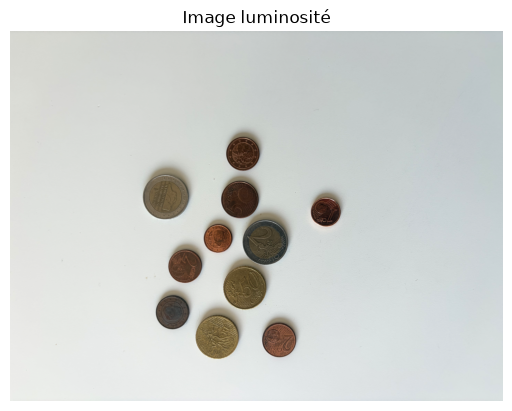

In [2]:
# Ameliorer la luminosté

from modules.luminosite import ameliorer_luminosite

image_lum = ameliorer_luminosite(image_originale)
plt.imshow(image_lum)
plt.title("Image luminosité")
plt.axis("off");


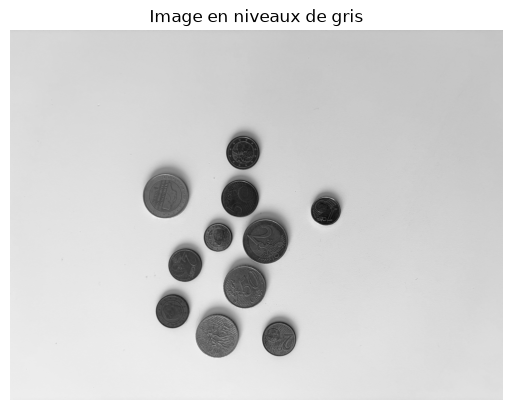

In [3]:
# Convertir l’image en niveaux de gris

from modules.niveaux_gris import convertir_en_gris

image_grise = convertir_en_gris(image_lum)

plt.imshow(image_grise, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off");


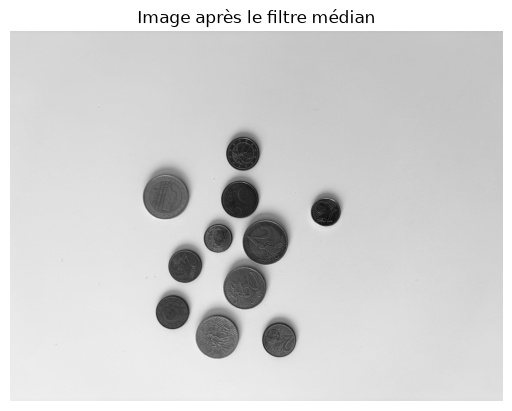

In [4]:
# Réduire le bruit avec un filtre médian

from modules.filtre_median import appliquer_filtre_median

image_filtree = appliquer_filtre_median(image_grise)

plt.imshow(image_filtree, cmap="gray")
plt.title("Image après le filtre médian")
plt.axis("off");


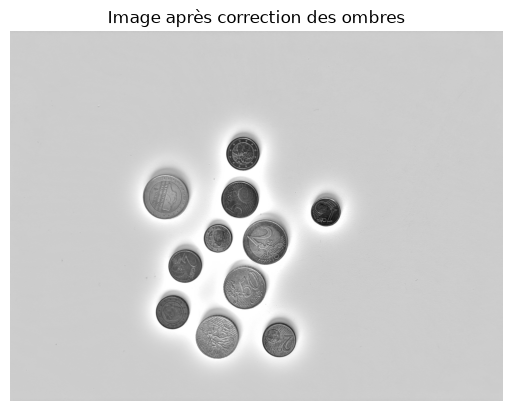

In [5]:
# Estimer l’éclairage et corriger les ombres

from modules.flou_gaussien import corriger_ombres

image_corrigee = corriger_ombres(image_filtree, sigma=150)
plt.imshow(image_corrigee, cmap="gray")
plt.title("Image après correction des ombres")
plt.axis("off");


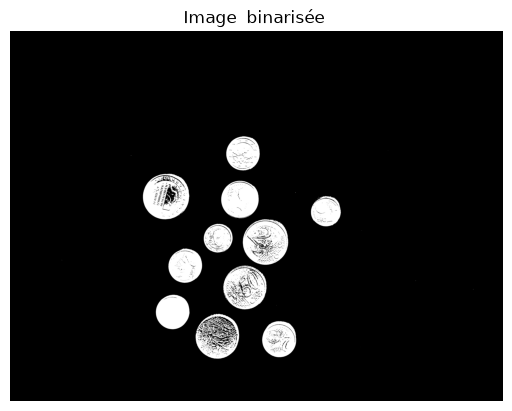

In [6]:
# Binariser l’image

from modules.binarisation import img_binarisee
image_binarisee = img_binarisee(image_corrigee)
plt.imshow(image_binarisee,cmap="gray");
plt.title("Image  binarisée ");
plt.axis("off");

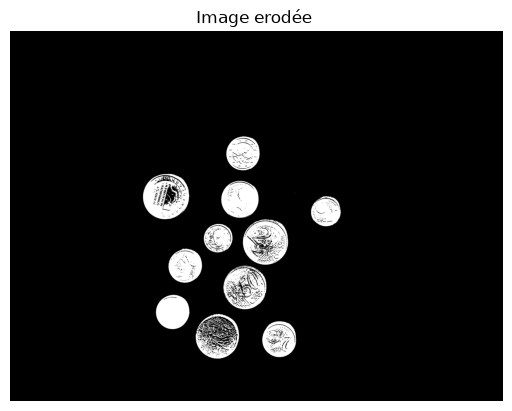

In [7]:
# nettoyer le masque binaire et améliorer les formes des pièces

from modules.erosion import appliquer_erosion

image_erodee = appliquer_erosion(image_binarisee, rayon=1)
plt.imshow(image_erodee,cmap="gray");
plt.title("Image erodée ");
plt.axis("off");


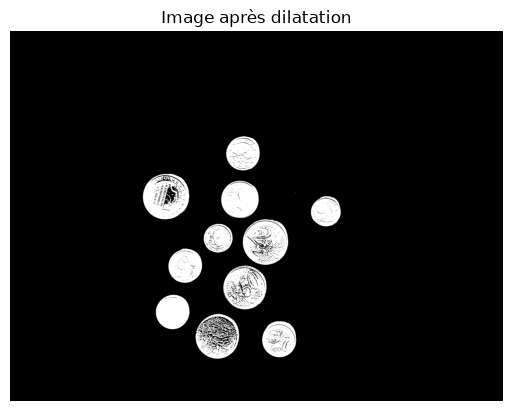

In [8]:
# Dilater le résultat après l’érosion

from modules.dilatation import appliquer_dilatation

image_dilatee = appliquer_dilatation(image_erodee, rayon=1)
plt.imshow(image_dilatee, cmap="gray")
plt.title("Image après dilatation")
plt.axis("off");


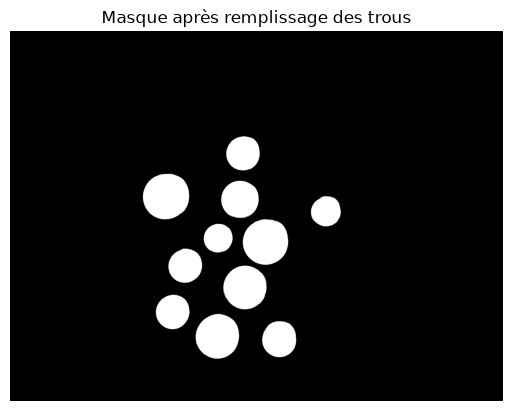

In [9]:
# Remplir les trous du masque

from modules.remplissage_trous import remplir_trous

image_sans_trous = remplir_trous(image_dilatee)
plt.imshow(image_sans_trous, cmap="gray")
plt.title("Masque après remplissage des trous")
plt.axis("off");


/Users/gregoryly/Desktop/signaux_monnaie/modules/nettoyage_masque.py:7: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  return remove_small_objects(image, min_size=taille_min)


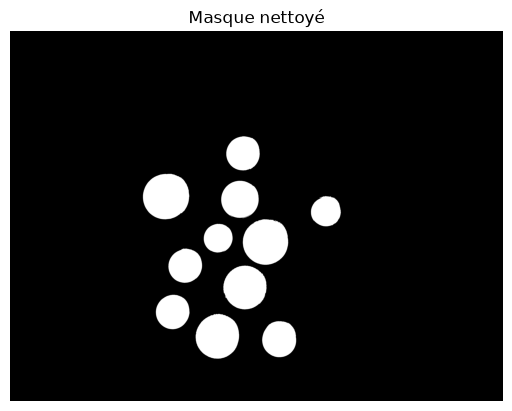

In [10]:
# Supprimer les petites régions parasites

from modules.nettoyage_masque import supprimer_petits_objets

image_masque_propre = supprimer_petits_objets(image_sans_trous, taille_min=5000)
plt.imshow(image_masque_propre, cmap="gray")
plt.title("Masque nettoyé")
plt.axis("off");


Nombre de régions détectées : 11


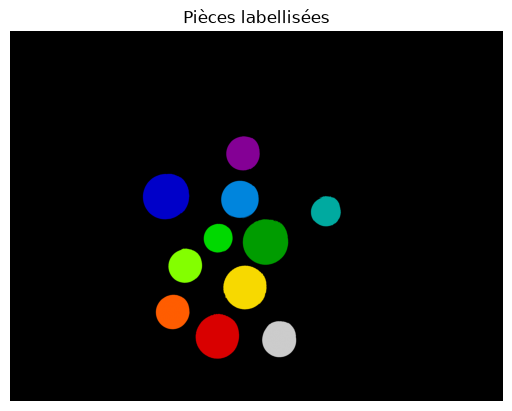

In [11]:
# Labelliser les pièces détectées

from modules.labellisation import labelliser_objets, compter_objets

image_labellisee = labelliser_objets(image_masque_propre, connectivite=1)
nombre_pieces = compter_objets(image_labellisee)
print(f"Nombre de régions détectées : {nombre_pieces}")
plt.imshow(image_labellisee, cmap="nipy_spectral")
plt.title("Pièces labellisées")
plt.axis("off");


In [12]:
# tableau des pieces + colorisation
from modules.labellisation import mesurer_objets,liste_aires
import pandas as pd


tableau_images = pd.DataFrame(mesurer_objets(image_labellisee,image_originale))
tableau_images

,piece,aire (en px),périmètre(en px),Couleur
0,1,121897.0,1338.68,Cuivre
1,2,224519.0,1825.93,Dorée
2,3,148461.0,1739.18,Cuivre
3,4,94635.0,1267.96,Cuivre
4,5,220329.0,1945.03,Bicolor
5,6,87761.0,1171.14,Cuivre
6,7,120794.0,1348.52,Cuivre
7,8,198659.0,1788.93,Dorée
8,9,122066.0,1324.48,Bicolor
9,10,204473.0,1753.93,Dorée


In [13]:
# colorisation
liste_aires(mesurer_objets(image_labellisee,image_originale))

1
121897.0
1338.68
Cuivre
2
224519.0
1825.93
Dorée
3
148461.0
1739.18
Cuivre
4
94635.0
1267.96
Cuivre
5
220329.0
1945.03
Bicolor
6
87761.0
1171.14
Cuivre
7
120794.0
1348.52
Cuivre
8
198659.0
1788.93
Dorée
9
122066.0
1324.48
Bicolor
10
204473.0
1753.93
Dorée
11
131269.0
1396.72
Cuivre
